The transition model scores every candidate destination, then turns those scores into a probability distribution over the candidate grid. The heatmap makes the destination choice inspectable. Here, **features** are the measured or derived inputs used to score each candidate. **own derivation**

## Model and inputs

For each candidate destination, the trained XGBoost model receives 13 features. The code builds one row per grid cell; state-level quantities are repeated across that frame’s candidates. **own derivation**

| Feature | Meaning in this implementation |
|---|---|
| `pass_distance`, `pass_angle`, `passer_speed` | Distance from carrier to candidate, signed angle between carrier velocity and the candidate direction, and carrier speed. **own derivation** |
| `target_pitch_control` | Pitch-control probability at the candidate location from the pass-probability model. The underlying control-field lineage is Spearman’s PPCF [@spearman2018beyond; @spearman2017]. |
| `target_xt_team`, `target_xt_opp` | Expected Threat grid values at the candidate for the attacking team and opponent orientation. xT is a state value associated with the location [@singh2018xt]. |
| `opp_pressure_line_index`, `team_pressure_line_index` | Count of the three estimated opponent or team pressure lines crossed by the candidate location. Lines are formed by clustering player x-coordinates after removing the goalkeeper; this implementation is a **design choice**. SkillCorner publishes pressure metrics as context for measuring pressure, but not this line-index formula [@skillcorner-pressure]. |
| `ball_drive_prob`, `xt_team_bc`, `xt_opp_bc`, `opp_pressure_index_bc`, `team_pressure_index_bc` | Carrier-state values repeated for each candidate: ball-drive loss probability, team/opponent xT at the carrier, and the two pressure-line counts at the carrier. **own derivation** |

The booster returns a score z_k per candidate k. The wrapper applies a numerically stable softmax over the candidates: p_k=exp(z_k−max z)/Σ_l exp(z_l−max z). Training uses grouped softmax cross-entropy over candidate destinations. This is a listwise choice objective; ListNet is a methodological reference for listwise ranking, not a claim that every implementation detail is identical [@cao2007listnet]. **own derivation**

The `ball_drive_prob` feature uses the loss probability in the transition model. The action-selection feature with the same name uses its complement, drive success, matching the respective original training pipelines. **own derivation**

Elapsed time is not an input. **design choice**

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope

This distribution chooses among the candidate destinations supplied for one state. It does not choose between passing and carrying, and its probabilities can change if the candidate set changes. **model scope** The source of truth for the feature construction and softmax is `PRESS/utils/transition.py`. **own derivation**

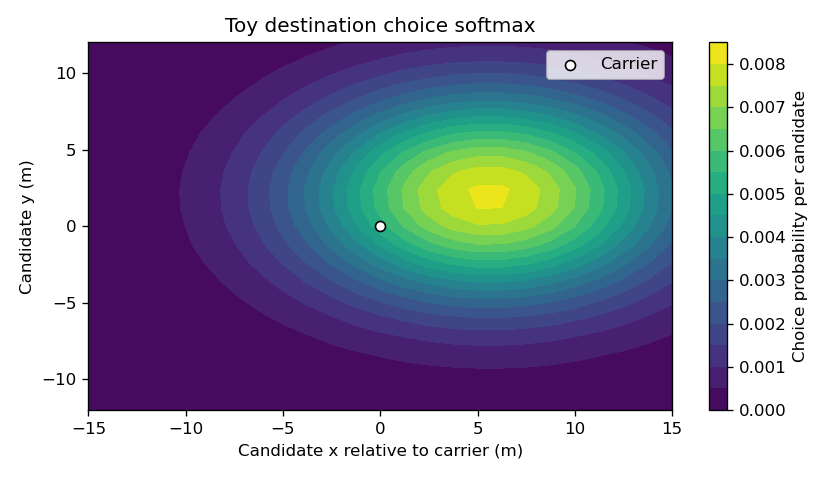

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Deterministic toy candidate scores; this demonstrates the wrapper's softmax normalization.
x,y=np.meshgrid(np.linspace(-15,15,25),np.linspace(-12,12,21)); score=-(x-4)**2/90-(y-2)**2/45+0.035*x
flat=score.ravel(); e=np.exp(flat-flat.max()); p=e/e.sum(); field=p.reshape(score.shape)
fig,ax=plt.subplots(figsize=(7,4)); im=ax.contourf(x,y,field,levels=18,cmap="viridis"); fig.colorbar(im,ax=ax,label="Choice probability per candidate"); ax.scatter([0],[0],c="white",edgecolor="black",label="Carrier"); ax.set(xlabel="Candidate x relative to carrier (m)",ylabel="Candidate y (m)",title="Toy destination choice softmax"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_03_transition.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.

The pitch view below uses the package plotting function and the computed values for frame 5, inside an action interval rather than at its start. It shows probability mass on the original candidate destinations, conditional on passing. Candidate fields use a coarse demonstration grid; the synthetic fixture and grid are not a benchmark.


choice probabilities: [7.58668435e-08 4.05473384e-06 1.14400551e-04 1.61350262e-03
 2.97610881e-03 2.67734984e-03 1.58597701e-04 2.17889334e-04
 1.70294021e-04 1.17063013e-04 1.32258690e-04 8.83227694e-05
 5.08468693e-05 8.06665454e-08 1.35651335e-05 4.87535835e-05
 1.04736360e-02 4.04139608e-03 7.55941495e-02 7.47683691e-04
 5.67326555e-04 5.43708156e-04 2.73136568e-04 1.37069524e-04
 1.12451678e-04 6.17525002e-05 9.99738177e-08 5.82016764e-05
 5.28760138e-04 4.58314316e-03 6.96328178e-04 1.40527144e-01
 1.99529249e-03 9.93905589e-04 8.97030439e-03 3.38555925e-04
 1.50639637e-04 1.31971305e-04 4.42552555e-05 2.06145273e-07
 2.93258490e-05 2.22888985e-03 2.92378590e-02 2.43755733e-03
 1.40032009e-03 1.13108568e-03 1.72212266e-03 2.24231966e-02
 4.09873493e-04 1.66243844e-04 9.63306957e-05 5.53318896e-05
 2.00528632e-07 2.71781118e-05 1.11873902e-03 1.66387353e-02
 1.22676254e-03 5.94641089e-01 2.31678691e-03 1.29768753e-03
 9.69140790e-04 3.64473235e-04 1.98950380e-04 1.10717672e-04
 5

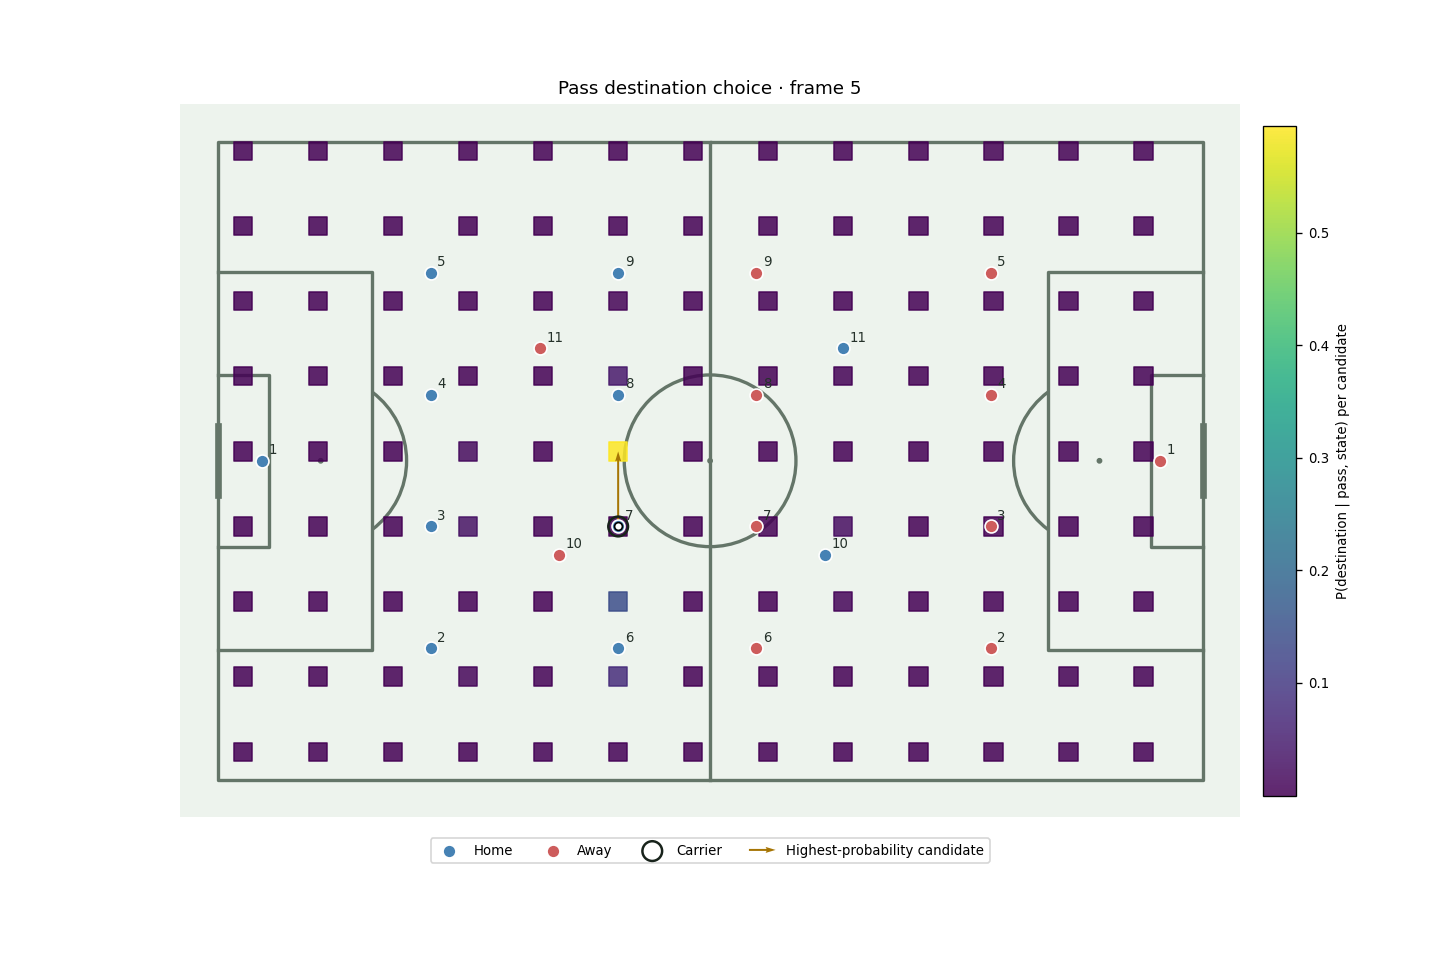

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
model.compute_ball_drive_loss(frame_id)
model.compute_transition_probabilities(frame_id, xT_grid)
result = model.get_ppcf_result(frame_id)
print("choice probabilities:", np.asarray(result["Transition probabilities"]))
print("probability sum:", float(np.sum(result["Transition probabilities"])))

from PRESS.visualization import plot_transition
fig, ax = plot_transition(model, frame_id)
out = Path("figures/vignette_03_transition_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
